# Instructions

(1) In mod08_sustainability_calculations, the energy usage is the product of the number of CPU cores, the number of runtime hours, and the number of kilowatts used per core. Update the function "compute_energy_kwh" to reflect this. _Hint_: You'll want to explore the data created in mod08_generate_emissions_data to learn the appropriate variable names.

(2) After you've updated (and saved) mod08_sustainability_calculations, run the cells in this notebook and answer the three discussion question. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mod08_generate_emissions_data import generate_data
from mod08_sustainability_calculations import (
    compute_energy_kwh,
    compute_emissions,
    emissions_by_region,
    compute_total_runtime
)

### Get the data

In [2]:
jobs, carbon_intensity, power_per_core_kw, max_cores_per_region = generate_data()

### Inspect the Provided Data

In [3]:
print("Jobs Dataset:")
print(jobs)

print("\nCarbon Intensity by Region (kg CO2 per kWh):")
for region, intensity in carbon_intensity.items():
    print(f"{region}: {intensity}")

Jobs Dataset:
    job_id  cpu_cores  runtime_hours
0        1          1           0.50
1        2          2           1.20
2        3          4           0.75
3        4          8           2.50
4        5          2           1.00
5        6          1           0.30
6        7         16           3.00
7        8          4           1.50
8        9          8           2.00
9       10          2           0.80
10      11          4           0.50
11      12          8           2.25
12      13          2           1.60
13      14          8           0.90
14      15         16           1.10

Carbon Intensity by Region (kg CO2 per kWh):
coal_heavy_region: 0.9
renewable_region: 0.05


### Compute Energy Usage

In [4]:
jobs_with_energy = compute_energy_kwh(jobs, power_per_core_kw)

print("Jobs with Energy Computed:")
print(jobs_with_energy)

total_energy = jobs_with_energy["energy_kwh"].sum()
print(f"\nTotal Energy Consumption: {total_energy:.4f} kWh")

Jobs with Energy Computed:
    job_id  cpu_cores  runtime_hours  energy_kwh
0        1          1           0.50        10.0
1        2          2           1.20        24.0
2        3          4           0.75        15.0
3        4          8           2.50        50.0
4        5          2           1.00        20.0
5        6          1           0.30         6.0
6        7         16           3.00        60.0
7        8          4           1.50        30.0
8        9          8           2.00        40.0
9       10          2           0.80        16.0
10      11          4           0.50        10.0
11      12          8           2.25        45.0
12      13          2           1.60        32.0
13      14          8           0.90        18.0
14      15         16           1.10        22.0

Total Energy Consumption: 398.0000 kWh


### Compute Emissions for Each Region

In [5]:
region_emissions = emissions_by_region(jobs_with_energy, carbon_intensity)

print("Total Emissions by Region (kg CO2):")
for region, emissions in region_emissions.items():
    print(f"{region}: {emissions:.4f}")

Total Emissions by Region (kg CO2):
coal_heavy_region: 358.2000
renewable_region: 19.9000


### Visualize Emissions by Region

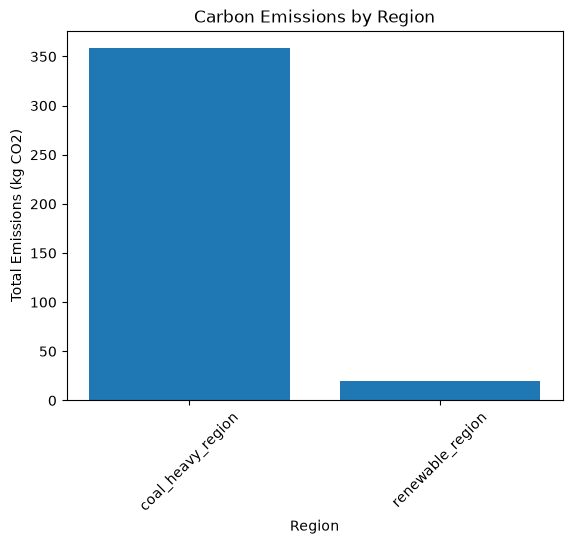

In [6]:
plt.figure()
plt.bar(region_emissions.keys(), region_emissions.values())
plt.xlabel("Region")
plt.ylabel("Total Emissions (kg CO2)")
plt.title("Carbon Emissions by Region")
plt.xticks(rotation=45)
plt.show()

### Scenario 1: All Jobs in Coal-Heavy Region

In [7]:
coal_region = max(carbon_intensity, key=carbon_intensity.get)
all_coal_emissions = compute_emissions(
    jobs_with_energy,
    carbon_intensity[coal_region]
)

all_coal_runtime = compute_total_runtime(jobs_with_energy, max_cores_per_region[coal_region])

print(f"All jobs in {coal_region}: {all_coal_emissions:.4f} kg CO2, Runtime: {all_coal_runtime:.2f} h")

All jobs in coal_heavy_region: 358.2000 kg CO2, Runtime: 7.10 h


### Scenario 2: All Jobs in Renewable Region

In [8]:
renewable_region = min(carbon_intensity, key=carbon_intensity.get)
all_renewable_emissions = compute_emissions(
    jobs_with_energy,
    carbon_intensity[renewable_region]
)

all_renewable_runtime = compute_total_runtime(jobs_with_energy, max_cores_per_region[renewable_region])

print(f"All jobs in {renewable_region}: {all_renewable_emissions:.4f} kg CO2, Runtime: {all_renewable_runtime:.2f} h")

All jobs in renewable_region: 19.9000 kg CO2, Runtime: 11.95 h


### Scenario 3: Assign High CPU Jobs to Renewable Region

In [9]:
# Decide which jobs to assign to renewable region
median = jobs_with_energy["cpu_cores"].median()

green_jobs = jobs_with_energy[jobs_with_energy["cpu_cores"] >= median]
dirty_jobs = jobs_with_energy[jobs_with_energy["cpu_cores"] < median]

# compute the new total emissions
smart_emissions = compute_emissions(green_jobs, carbon_intensity[renewable_region]) + \
                  compute_emissions(dirty_jobs, carbon_intensity[coal_region])

# compute the new total runtime (with parallelization)
smart_runtime = max(compute_total_runtime(green_jobs, max_cores_per_region[renewable_region]),
                    compute_total_runtime(dirty_jobs, max_cores_per_region[coal_region]))

print(f"High-CPU jobs to {renewable_region}: {smart_emissions:.4f} kg CO2, Runtime: {smart_runtime:.2f} h")

High-CPU jobs to renewable_region: 111.7000 kg CO2, Runtime: 10.10 h


### Strategy Comparison Plot

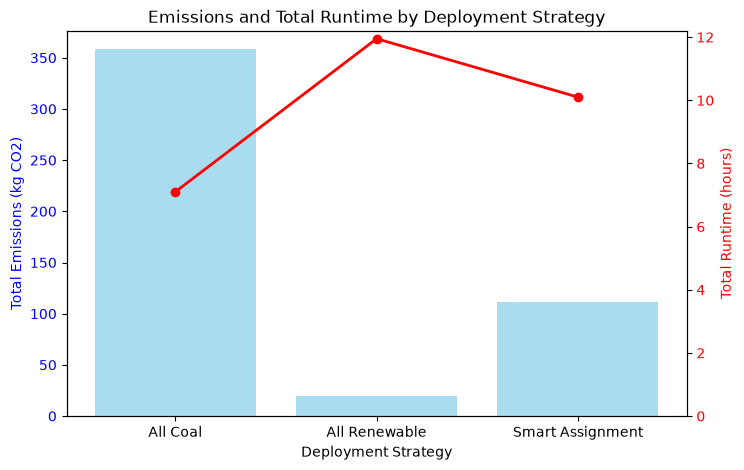

In [10]:
# Prepare data
strategy_names = ["All Coal", "All Renewable", "Smart Assignment"]
emission_values = [all_coal_emissions, all_renewable_emissions, smart_emissions]
runtime_values = [all_coal_runtime, all_renewable_runtime, smart_runtime]

# Plot
fig, ax1 = plt.subplots(figsize=(8,5))

# Bar chart for emissions
ax1.bar(strategy_names, emission_values, color='skyblue', alpha=0.7)
ax1.set_ylabel("Total Emissions (kg CO2)", color='blue')
ax1.set_xlabel("Deployment Strategy")
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_title("Emissions and Total Runtime by Deployment Strategy")

# Line chart for runtime
ax2 = ax1.twinx()
ax2.plot(strategy_names, runtime_values, color='red', marker='o', linewidth=2)
ax2.set_ylabel("Total Runtime (hours)", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(bottom=0)

plt.show()

# Discussion Questions

### Similar to what we did in Scenario 3, let's look at different quantile values to decide what proportion of jobs to assign to renewable energy.

In [11]:
# Decide which jobs to assign to renewable region
cpu_threshold = jobs_with_energy["cpu_cores"].quantile(
    # enter a choice between 0 and 1 here
    0.7
)

green_jobs = jobs_with_energy[jobs_with_energy["cpu_cores"] >= cpu_threshold]
dirty_jobs = jobs_with_energy[jobs_with_energy["cpu_cores"] < cpu_threshold]

# compute the new total emissions
smart_emissions = compute_emissions(green_jobs, carbon_intensity[renewable_region]) + \
                  compute_emissions(dirty_jobs, carbon_intensity[coal_region])

# compute the new total runtime (with parallelization)
smart_runtime = max(compute_total_runtime(green_jobs, max_cores_per_region[renewable_region]),
                    compute_total_runtime(dirty_jobs, max_cores_per_region[coal_region]))

print(f"High-CPU jobs to {renewable_region}: {smart_emissions:.4f} kg CO2, Runtime: {smart_runtime:.2f} h")

High-CPU jobs to renewable_region: 158.4500 kg CO2, Runtime: 8.85 h


### Comment on what you believe is the most appropriate threshold given the tradeoff between emissions and runtime.

I think a threshold of around 0.5-0.7 is most appropriate. With this threshold, we still maintain emissions less than half the amount of the emissions of the jobs in the coal-heavy region, but we also don't increase the runtime much in comparison to the coal-heavy region, while not increasing emissions that much when compared to the high-CPU jobs in the renewable region, given the decrease in runtime we get for our threshold.

### In this notebook, we calculate emissions and runtimes as the inputs of our cost-benefit analysis. Name and explain at least one other cost or benefit that is not considered here.

Another cost-benefit analysis not considered is the actual cost of these jobs in renewable regions compared to coal regions. Setting up sustainable energy sources can have different costs than using coal.

### List at least two different stakeholders that would be affected by a strategic decision regarding the assignment of resources explored in this notebook. In your opinion, which stakeholder's interests are most compelling?

Builders of data centers, as well as other businesses, invested in other industrial buildings, such as the creation of power plants. I find the industrial builders' interests more compelling because it introduces another cost-benefit analysis not yet considered in this assignment, which is the availability of resources such as coal, and what can happen if we introduce another business that can lead to its depletion.